# 07 — Três caminhos para isolar o sinal real

Depois do nb06 confirmar viés grave de equipamento (probe F1m = 0.91), testamos 3 abordagens:

- **A** — Repeated CV no Meditron-only (IC95% honesto do F1m sem viés).
- **B** — Classificação por **ciclo respiratório** (crackles/wheezes) — alvo objetivo, dataset mais balanceado, anotado em todos os `.txt`.
- **C** — **Residualização** de features sobre equipamento (remove componente linear explicada pelo dispositivo, retreina no dataset completo).

Final: tabela comparativa dos resultados.

In [1]:
import sys, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score, classification_report
from xgboost import XGBClassifier

from src import config, metadata, features
import librosa

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
X_full = feats_df[FEATURE_COLS].values
le_y = LabelEncoder(); y_full = le_y.fit_transform(feats_df['label_multi'])
g_full = feats_df['patient_id'].values
CLASSES = list(le_y.classes_)
print(f'Dataset: {X_full.shape}, classes={CLASSES}, pacientes={len(np.unique(g_full))}')

Dataset: (851, 78), classes=['COPD', 'Healthy', 'URTI'], pacientes=104


---
## A — Repeated 3-fold × 10 no Meditron-only

Os 48 pacientes do Meditron (8 COPD + 26 Healthy + 14 URTI) são o cenário sem viés.
3-fold porque COPD só tem 8 pacientes; 10 repetições com seeds diferentes pra IC.

In [3]:
mask = feats_df['equipment'] == 'WelchAllyn Meditron'
feats_med = feats_df[mask].reset_index(drop=True)
X_m = feats_med[FEATURE_COLS].values
y_m = le_y.transform(feats_med['label_multi'])
g_m = feats_med['patient_id'].values
print(f'Meditron-only: {len(feats_med)} gravações, {len(np.unique(g_m))} pacientes')

Meditron-only: 94 gravações, 48 pacientes


In [4]:
def make_models():
    return {
        'KNN':    Pipeline([('s', StandardScaler()),
                             ('c', KNeighborsClassifier(n_neighbors=5, weights='distance'))]),
        'LDA':    Pipeline([('s', StandardScaler()),
                             ('c', LinearDiscriminantAnalysis())]),
        'LogReg': Pipeline([('s', StandardScaler()),
                             ('c', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
        'XGB':    Pipeline([('s', StandardScaler()),
                             ('c', XGBClassifier(n_estimators=200, max_depth=3,
                                                  learning_rate=0.05, eval_metric='mlogloss', n_jobs=1))]),
    }

def patient_metrics(y_true, y_pred, groups):
    d = pd.DataFrame({'g': groups, 'y': y_true, 'p': y_pred})
    a = d.groupby('g').agg(y=('y','first'), p=('p', lambda s: s.value_counts().idxmax()))
    return a['y'].values, a['p'].values

rows_A = []
t0 = time.time()
for rep in range(10):
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42+rep)
    for name, model in make_models().items():
        p = cross_val_predict(model, X_m, y_m, groups=g_m, cv=cv, n_jobs=1)
        f1r = f1_score(y_m, p, average='macro')
        yt, yp = patient_metrics(y_m, p, g_m)
        f1p = f1_score(yt, yp, average='macro')
        ap  = accuracy_score(yt, yp)
        rows_A.append(dict(model=name, repeat=rep, f1m_rec=f1r, f1m_pat=f1p, acc_pat=ap))
    if (rep+1) % 5 == 0:
        print(f'  rep {rep+1}/10  ({time.time()-t0:.0f}s)')
A_df = pd.DataFrame(rows_A)
print(f'A — done ({time.time()-t0:.0f}s)')

  rep 5/10  (7s)


  rep 10/10  (11s)
A — done (11s)


In [5]:
def summary_table(df, label):
    s = df.groupby('model').agg(
        f1m_pat_mu=('f1m_pat','mean'), f1m_pat_sd=('f1m_pat','std'),
        acc_pat_mu=('acc_pat','mean'), acc_pat_sd=('acc_pat','std'),
    ).round(3)
    s['F1m paciente'] = s.apply(lambda r: f'{r.f1m_pat_mu:.3f} ± {r.f1m_pat_sd:.3f}', axis=1)
    s['Acc paciente']  = s.apply(lambda r: f'{r.acc_pat_mu:.3f} ± {r.acc_pat_sd:.3f}', axis=1)
    return s.sort_values('f1m_pat_mu', ascending=False)[['F1m paciente','Acc paciente']]

summary_A = summary_table(A_df, 'A')
print('A — Meditron-only (10×3-fold):')
summary_A

A — Meditron-only (10×3-fold):


,F1m paciente,Acc paciente
model,,
KNN,0.707 ± 0.031,0.681 ± 0.035
LDA,0.635 ± 0.074,0.573 ± 0.077
XGB,0.615 ± 0.036,0.583 ± 0.034
LogReg,0.597 ± 0.049,0.531 ± 0.049


---
## B — Classificação por ciclo respiratório

Cada `.txt` lista intervalos `start, end, crackles, wheezes`. Cortamos cada gravação nos seus ciclos e extraímos as 78 features por **ciclo individual**. Rótulo 4-classe: `normal / crackles / wheezes / both`.

Vantagens:
- Muito mais amostras (~6.9k ciclos).
- Classes mais balanceadas que diagnóstico.
- Alvo objetivo (achado auscultaório), não inferido.

Atenção: o **split continua por paciente**. Ciclos de um mesmo paciente não podem aparecer em treino+teste.

In [6]:
# Construir DF de ciclos com diagnóstico
rec_df = metadata.build_recordings_dataframe()
cycles_df = metadata.build_cycles_dataframe(rec_df)
cycles_df['label_cycle'] = np.where(
    (cycles_df['crackles']==0) & (cycles_df['wheezes']==0), 'normal',
    np.where((cycles_df['crackles']==1) & (cycles_df['wheezes']==0), 'crackles',
    np.where((cycles_df['crackles']==0) & (cycles_df['wheezes']==1), 'wheezes', 'both')))
print(f'Ciclos totais: {len(cycles_df)}')
print(cycles_df['label_cycle'].value_counts())

Ciclos totais: 6898
label_cycle
normal      3642
crackles    1864
wheezes      886
both         506
Name: count, dtype: int64


In [7]:
# Extrair features por ciclo (1 load por wav, vários cortes) — cacheado em CSV
CYC_CSV = config.PROCESSED_DIR / 'features_cycles.csv'

if CYC_CSV.exists():
    print(f'Cache encontrado: {CYC_CSV}')
    cyc_feats = pd.read_csv(CYC_CSV)
else:
    # mapa wav -> filas do cycles_df
    groups_per_wav = dict(list(cycles_df.groupby('filename')))
    wav_paths = rec_df.set_index('filename')['wav_path'].to_dict()
    rows = []
    t0 = time.time()
    for fname, grp in tqdm(groups_per_wav.items(), total=len(groups_per_wav), desc='áudios'):
        try:
            y, sr = librosa.load(wav_paths[fname], sr=config.SAMPLE_RATE, mono=True)
        except Exception:
            continue
        for _, c in grp.iterrows():
            feats = features.extract_segment(y, sr, float(c['start']), float(c['end']))
            if feats is None:
                continue
            feats['filename'] = fname
            feats['patient_id'] = int(c['patient_id'])
            feats['cycle_idx'] = int(c['cycle_idx'])
            feats['label_cycle'] = c['label_cycle']
            feats['duration'] = float(c['duration'])
            rows.append(feats)
    cyc_feats = pd.DataFrame(rows)
    cyc_feats.to_csv(CYC_CSV, index=False)
    print(f'Extraído {len(cyc_feats)} ciclos em {time.time()-t0:.0f}s')

print(cyc_feats.shape)
print(cyc_feats['label_cycle'].value_counts())

áudios:   0%|          | 0/920 [00:00<?, ?it/s]

Extraído 6898 ciclos em 294s
(6898, 83)
label_cycle
normal      3642
crackles    1864
wheezes      886
both         506
Name: count, dtype: int64


In [8]:
# Modelagem dos ciclos
FCOLS_CYC = [c for c in cyc_feats.columns
             if c not in ('filename','patient_id','cycle_idx','label_cycle','duration')]
Xc = cyc_feats[FCOLS_CYC].values
le_c = LabelEncoder(); yc = le_c.fit_transform(cyc_feats['label_cycle'])
gc = cyc_feats['patient_id'].values
CYC_CLASSES = list(le_c.classes_)
print(f'Xc={Xc.shape}  classes={CYC_CLASSES}  pacientes={len(np.unique(gc))}')

rows_B = []
t0 = time.time()
for rep in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42+rep)
    for name, model in make_models().items():
        p = cross_val_predict(model, Xc, yc, groups=gc, cv=cv, n_jobs=1)
        f1r = f1_score(yc, p, average='macro')
        ar  = accuracy_score(yc, p)
        rows_B.append(dict(model=name, repeat=rep, f1m_cyc=f1r, acc_cyc=ar))
    print(f'  rep {rep+1}/5  ({time.time()-t0:.0f}s)')
B_df = pd.DataFrame(rows_B)

Xc=(6898, 78)  classes=['both', 'crackles', 'normal', 'wheezes']  pacientes=126


  rep 1/5  (20s)


  rep 2/5  (37s)


  rep 3/5  (55s)


  rep 4/5  (73s)


  rep 5/5  (91s)


In [9]:
summary_B = B_df.groupby('model').agg(
    f1_mu=('f1m_cyc','mean'), f1_sd=('f1m_cyc','std'),
    acc_mu=('acc_cyc','mean'), acc_sd=('acc_cyc','std'),
).round(3)
summary_B['F1m ciclo'] = summary_B.apply(lambda r: f'{r.f1_mu:.3f} ± {r.f1_sd:.3f}', axis=1)
summary_B['Acc ciclo']  = summary_B.apply(lambda r: f'{r.acc_mu:.3f} ± {r.acc_sd:.3f}', axis=1)
summary_B = summary_B.sort_values('f1_mu', ascending=False)[['F1m ciclo','Acc ciclo']]
print('B — classificação por ciclo (5×5-fold):')
summary_B

B — classificação por ciclo (5×5-fold):


,F1m ciclo,Acc ciclo
model,,
LogReg,0.348 ± 0.002,0.414 ± 0.002
LDA,0.318 ± 0.001,0.501 ± 0.001
XGB,0.314 ± 0.003,0.531 ± 0.002
KNN,0.305 ± 0.001,0.465 ± 0.003


---
## C — Residualização de features sobre equipamento

Para cada feature, ajustamos uma regressão linear `feature ~ equipamento (one-hot)` e usamos os **resíduos** como novas features. Intuitivamente: removemos a parte da feature que é prevista pelo equipamento.

Treinamos os 4 modelos sobre as features residualizadas no dataset completo (104 pacientes). Se F1m residualizado ≈ F1m original → o sinal não era apenas equipamento. Se cair muito → era atalho.

In [10]:
# Residualização 
ohe = OneHotEncoder(sparse_output=False, drop=None).fit(feats_df[['equipment']])
E = ohe.transform(feats_df[['equipment']])
lr = LinearRegression().fit(E, X_full)
X_resid = X_full - lr.predict(E)
print('Resíduos shape:', X_resid.shape)
print('Std médio original :', X_full.std(0).mean().round(3))
print('Std médio resíduos:', X_resid.std(0).mean().round(3))

Resíduos shape: (851, 78)
Std médio original : 27.02
Std médio resíduos: 23.554


In [11]:
# Repeated CV no dataset completo COM features residualizadas
rows_C = []
t0 = time.time()
for rep in range(10):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42+rep)
    for name, model in make_models().items():
        p = cross_val_predict(model, X_resid, y_full, groups=g_full, cv=cv, n_jobs=1)
        f1r = f1_score(y_full, p, average='macro')
        yt, yp = patient_metrics(y_full, p, g_full)
        f1p = f1_score(yt, yp, average='macro')
        ap  = accuracy_score(yt, yp)
        rows_C.append(dict(model=name, repeat=rep, f1m_rec=f1r, f1m_pat=f1p, acc_pat=ap))
    if (rep+1) % 5 == 0:
        print(f'  rep {rep+1}/10  ({time.time()-t0:.0f}s)')
C_df = pd.DataFrame(rows_C)
summary_C = summary_table(C_df, 'C')
print('C — features residualizadas (dataset completo, 10×5-fold):')
summary_C

  rep 5/10  (21s)


  rep 10/10  (43s)
C — features residualizadas (dataset completo, 10×5-fold):


,F1m paciente,Acc paciente
model,,
LogReg,0.633 ± 0.030,0.800 ± 0.017
XGB,0.611 ± 0.045,0.786 ± 0.024
LDA,0.523 ± 0.046,0.727 ± 0.019
KNN,0.461 ± 0.027,0.709 ± 0.016


---
## Comparação final

In [12]:
# extrair média/sd numéricos para juntar tudo numa tabela
def to_stats(df, col, suffix):
    s = df.groupby('model')[col].agg(['mean','std']).round(3)
    s.columns = [f'{suffix}_mu', f'{suffix}_sd']
    return s

tA = to_stats(A_df, 'f1m_pat', 'A_pat')
tB = to_stats(B_df, 'f1m_cyc', 'B_cyc')
tC = to_stats(C_df, 'f1m_pat', 'C_pat')

# também: o nb04 (sem viés removido, sem ciclo) — recalculamos rapidamente para baseline
rows_base = []
for rep in range(10):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42+rep)
    for name, model in make_models().items():
        p = cross_val_predict(model, X_full, y_full, groups=g_full, cv=cv, n_jobs=1)
        yt, yp = patient_metrics(y_full, p, g_full)
        rows_base.append(dict(model=name, repeat=rep,
                               f1m_pat=f1_score(yt, yp, average='macro')))
base_df = pd.DataFrame(rows_base)
tBASE = to_stats(base_df, 'f1m_pat', 'BASE_pat')

comp = tBASE.join(tA, how='outer').join(tC, how='outer').join(tB, how='outer')

def fmt_pair(mu, sd):
    if pd.isna(mu): return '—'
    return f'{mu:.3f} ± {sd:.3f}'
pretty = pd.DataFrame({
    'BASELINE F1m pac. (full, com viés)':     [fmt_pair(comp.loc[m,'BASE_pat_mu'], comp.loc[m,'BASE_pat_sd']) for m in comp.index],
    'A  Meditron-only F1m paciente':           [fmt_pair(comp.loc[m,'A_pat_mu'],    comp.loc[m,'A_pat_sd'])    for m in comp.index],
    'C  Residualizado F1m paciente':           [fmt_pair(comp.loc[m,'C_pat_mu'],    comp.loc[m,'C_pat_sd'])    for m in comp.index],
    'B  F1m por ciclo (tarefa diferente)':     [fmt_pair(comp.loc[m,'B_cyc_mu'],    comp.loc[m,'B_cyc_sd'])    for m in comp.index],
}, index=comp.index).sort_index()
pretty

,"BASELINE F1m pac. (full, com viés)",A Meditron-only F1m paciente,C Residualizado F1m paciente,B F1m por ciclo (tarefa diferente)
model,,,,
KNN,0.610 ± 0.035,0.707 ± 0.031,0.461 ± 0.027,0.305 ± 0.001
LDA,0.598 ± 0.043,0.635 ± 0.074,0.523 ± 0.046,0.318 ± 0.001
LogReg,0.586 ± 0.049,0.597 ± 0.049,0.633 ± 0.030,0.348 ± 0.002
XGB,0.485 ± 0.028,0.615 ± 0.036,0.611 ± 0.045,0.314 ± 0.003


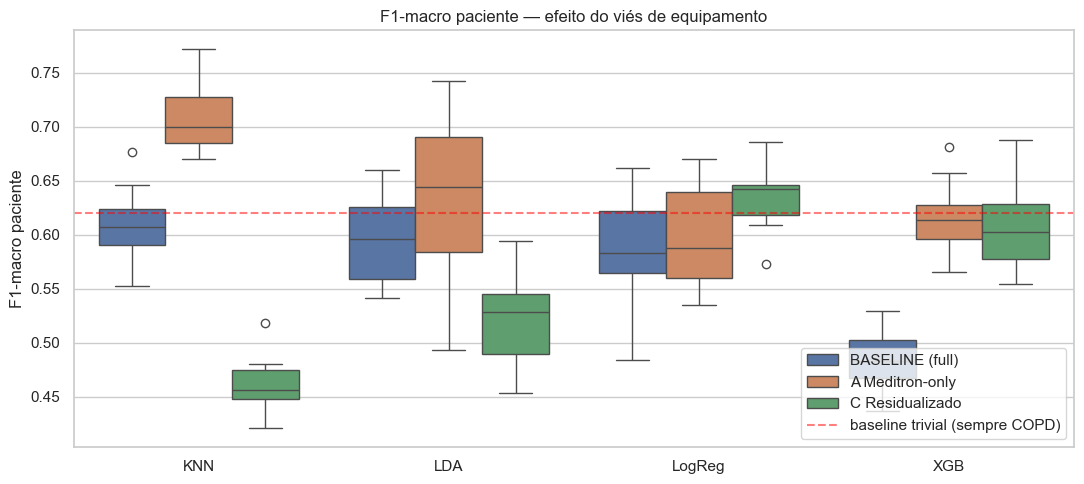

In [13]:
# Visualização — apenas as 3 condições comparáveis (mesmo alvo: diagnóstico)
merge_long = []
for cond, df, col in [('BASELINE (full)', base_df, 'f1m_pat'),
                       ('A Meditron-only', A_df,    'f1m_pat'),
                       ('C Residualizado', C_df,    'f1m_pat')]:
    tmp = df[['model', col]].copy(); tmp.columns = ['model', 'F1m_pat']
    tmp['cond'] = cond
    merge_long.append(tmp)
long_df = pd.concat(merge_long, ignore_index=True)

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=long_df, x='model', y='F1m_pat', hue='cond',
             order=['KNN','LDA','LogReg','XGB'], ax=ax)
ax.set_title('F1-macro paciente — efeito do viés de equipamento')
ax.set_ylabel('F1-macro paciente'); ax.set_xlabel('')
ax.axhline(0.62, color='red', linestyle='--', alpha=0.5, label='baseline trivial (sempre COPD)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## Como ler

- **BASELINE → A**: se A < BASELINE, parte do número original era viés de equipamento. Se A ≥ BASELINE, o Meditron tem sinal suficiente sozinho.
- **BASELINE → C**: se C cai com residualização → as features carregam informação de equipamento que era útil pra discriminar Healthy/URTI. Se C ≈ BASELINE → o sinal não-equipamento ainda permite separar.
- **B**: tarefa diferente (crackles/wheezes por ciclo). Vale comparar entre modelos, **não** com diagnóstico.

**Decisão prática:** o cenário mais honesto pro projeto é alguma combinação de A (Meditron-only) e C (residualizado). B é a tarefa que escala mais facilmente e pode ser o produto principal do assistente.